# Phase 1: CO from sensors, hour and weather

**Question.** Can a discrete Bayesian network estimate the true CO level better than the hour of day alone, using only what a deployed low-cost device can observe?

**Query.** P(CO | hour, T, RH, S1 … S5). Hour and weather are root inputs. CO is the hidden quantity of interest: it is missing on about 18% of hours, and EM fills those in during fitting. Each sensor depends on CO and the weather.

        hour ──► CO ──► S1 … S5 ◄── T, RH

**Setup.**
- Data: UCI Air Quality, rows with missing hour or weather dropped (8,991 hours left).
- Split: whole weeks shuffled into train / val / test (`blocked_split`, seed from `config`).
- Discretization: 3 quantile bins (low / medium / high), edges fit on train only.
- Model: `DiscreteBN` fit with MAP-EM (Laplace α = 1).
- Baseline: `HourOnlyBaseline`, P(CO | hour).
- All comparisons are scored on **val**. Test is held out for the final report.

**Results (val, n = 2,064 hours with a reference reading).**
- Accuracy 0.828 vs 0.591 for the hour-only baseline (+23.7 pp). Mean log-likelihood −0.662 vs −0.854.
- As a concentration estimate (the posterior-weighted mean over bins), MAE is 0.556 mg/m³. The resolution floor for 3 bins is 0.526 mg/m³, so most of the remaining error comes from the coarse bins rather than the model.

**Assumptions.**
- **Sensors are conditionally independent given CO and the weather.** Each sensor's CPT is P(S | CO, T, RH), with no sensor–sensor edges and no other gases. This is known not to hold: the sensors share responses to other traffic gases. The model therefore counts overlapping evidence more than once and is overconfident. Dropping one sensor barely changes accuracy (see the drop-one-sensor ablation). Phase 2 adds the other gases as parents.
- **CO depends only on the hour of day.** No weekday, season or weather effect on CO itself. Phase 3b adds a latent EmissionRegime driven by hour and weekday.
- **Hours are independent.** Each hour is treated as a separate sample, with no dependence on the previous one. The HMM extension relaxes this. The blocked split keeps neighbouring hours on the same side of the split, so validation scores aren't inflated by near-duplicate hours.
- **The relationships don't change over time.** One set of CPTs covers the whole year, so sensor drift and seasonal changes in sensor response are ignored.
- **Missing values are missing at random.** EM uses hours with no CO reading by averaging over CO's posterior. That is valid only if whether CO is missing doesn't depend on the CO value itself once the observed variables are taken into account. Hours with a missing sensor reading are kept, and that sensor is marginalized out.
- **The reference analyzer is the ground truth.** Its own measurement error is ignored.
- **Three bins are enough.** CO, the sensors and the weather are cut into train-quantile terciles, so variation within a bin is lost. That loss is the resolution floor reported in section 10. The concentration estimate assumes each bin is well represented by its training mean.
- **Inputs are always observed.** Hour, T and RH have no CPT. The 366 hours with missing weather are dropped instead of imputed.
- **Prior.** Laplace smoothing (α = 1) on every CPT row, so a parent combination never seen in training gets a near-uniform distribution instead of zeros.

## 1. Load

In [ ]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cse250a.modules.config import config
from cse250a.modules.core import TIME_CARDS, Gas, Network, Sensor, Time, Weather
from cse250a.modules.data import Discretizer, blocked_split, load_air_quality
from cse250a.modules.eval import (
    bin_means,
    concentration_error,
    expected_concentration,
    resolution_floor,
)
from cse250a.modules.models import DiscreteBN, HourOnlyBaseline

PHASE = "phase1"
RESULTS = config.paths.results_dir
FIGS = config.paths.figures_dir / PHASE

In [ ]:
df = load_air_quality( config.paths.data_dir / "air_quality" / "AirQualityUCI.csv")
print(df.shape)
df.isna().mean().round(3).rename("fraction missing").to_frame().T

(9357, 17)


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,hour,dow,is_weekday,season
fraction missing,0.18,0.039,0.902,0.039,0.039,0.175,0.039,0.175,0.039,0.039,0.039,0.039,0.039,0.0,0.0,0.0,0.0


## 2. Choose the variables, and drop rows with missing inputs

These are this experiment's choices; they live here in the notebook, not in `src/`.

- **target:** CO
- **weather:** Temp: -1.9 to 44.6, RH: 9.2 to 88.7
- **sensors:** S1 = "PT08.S1(CO)", S2 = "PT08.S2(NMHC)", S3 = "PT08.S3(NOx)", S4 = "PT08.S4(NO2)", S5 = "PT08.S5(O3)"

We drop rows with missing H, W because they are inputs to the model. They are root nodes and the parents of CO and the sensors, so if we don't have them, we cannot fill in information for the CPT row that needs them, and we have no way of getting that information, so it makes sense to just drop those rows. 

In [ ]:
target = Gas.CO
weather = (Weather.T, Weather.RH)
sensors = tuple(Sensor)

before = len(df)
df = df.dropna(subset=[Time.HOUR, *weather])
print(f"dropped {before - len(df)} rows with missing weather; {len(df)} left")

df[list(weather)].agg(["min", "max"])

dropped 366 rows with missing weather; 8991 left


,T,RH
min,-1.9,9.2
max,44.6,88.7


## 3. Split

`blocked_split` shuffles whole **weeks** into train / val / test, so neighbouring hours (which are nearly identical) don't end up on both sides of the split.

In [ ]:
train_raw, val_raw, test_raw = blocked_split(df, seed=config.seed)
print({name: len(d) for name, d in [("train", train_raw), ("val", val_raw), ("test", test_raw)]})

{'train': 4500, 'val': 2259, 'test': 2232}


## 4. Discretize

Fit the bin edges on **train only**, then apply the same edges to every split. 3 quantile bins → states 0 / 1 / 2 = low / medium / high, roughly a third of training hours each. `disc.cards` records how many bins each column got.

In [ ]:
binned = [target, *sensors, *weather]
disc = Discretizer(n_bins=3).fit(train_raw, binned)
train, val, test = (disc.transform(d) for d in (train_raw, val_raw, test_raw))

cards = {**disc.cards, **TIME_CARDS}
print("cards:", {str(k): v for k, v in cards.items() if k in binned or k == Time.HOUR})
train[binned].head()

cards: {'CO(GT)': 3, 'PT08.S1(CO)': 3, 'PT08.S2(NMHC)': 3, 'PT08.S3(NOx)': 3, 'PT08.S4(NO2)': 3, 'PT08.S5(O3)': 3, 'T': 3, 'RH': 3, 'hour': 24}


,CO(GT),PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH
datetime,,,,,,,,
2004-03-17 18:00:00,2.0,2.0,2.0,1.0,2.0,2.0,2.0,0.0
2004-03-17 19:00:00,2.0,2.0,2.0,0.0,2.0,2.0,1.0,0.0
2004-03-17 20:00:00,2.0,2.0,2.0,0.0,2.0,2.0,1.0,1.0
2004-03-17 21:00:00,2.0,2.0,2.0,0.0,2.0,2.0,1.0,1.0
2004-03-17 22:00:00,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0


## 5. Build the network

```
   hour ──► CO ──► S1 … S5 ◄── T, RH
```

`structure` maps each node to its parents. Every key gets a CPT; hour, T and RH appear only as parents, so they're inputs. `validate(train.columns)` catches typos, cycles, missing cards and missing columns before anything is fitted.

In [ ]:
network = Network(
    structure={
        target: (Time.HOUR,),
        **{s: (target, *weather) for s in sensors},
    },
    cards=cards,
).validate(train.columns)

# print("inputs:", network.inputs)
# print("\n")
print(network)

Network(6 nodes, inputs: hour, T, RH)
          CO(GT) | hour                          CPT shape (24, 3)
     PT08.S1(CO) | CO(GT), T, RH                 CPT shape (3, 3, 3, 3)
   PT08.S2(NMHC) | CO(GT), T, RH                 CPT shape (3, 3, 3, 3)
    PT08.S3(NOx) | CO(GT), T, RH                 CPT shape (3, 3, 3, 3)
    PT08.S4(NO2) | CO(GT), T, RH                 CPT shape (3, 3, 3, 3)
     PT08.S5(O3) | CO(GT), T, RH                 CPT shape (3, 3, 3, 3)


## 6. Fit

EM over every training row. CO is missing on some rows, and EM uses those too, weighting each possible CO value by its posterior. `result` keeps the objective per iteration. It must never go down (`is_monotone`).

3 iterations, converged: True, monotone: True


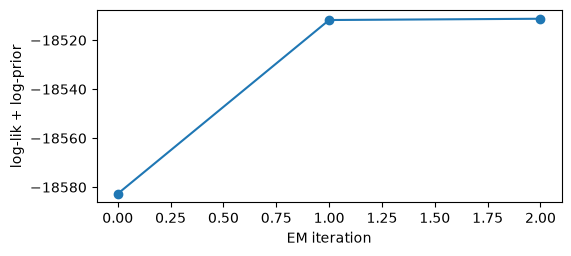

In [ ]:
bn = DiscreteBN(network).fit(train)
r = bn.result
print(f"{r.n_iter} iterations, converged: {r.converged}, monotone: {r.is_monotone()}")

fig, ax = plt.subplots(figsize=(6, 2.5))
ax.plot(r.history, marker="o")
ax.set_xlabel("EM iteration"); ax.set_ylabel("log-lik + log-prior")
plt.show()

## 7. Data Check

In [ ]:
# P(CO | hour), first hours
bn.cpts[target].to_frame().round(2).head(6) 

,0,1,2
hour,,,
0,0.26,0.56,0.18
1,0.49,0.41,0.10
2,0.75,0.20,0.05
3,0.83,0.13,0.04
4,0.91,0.07,0.02
5,0.93,0.06,0.01


In [ ]:
# P(S1 | CO, T, RH)
bn.cpts[Sensor.S1].to_frame().round(2).head(9)

0     1     2
CO(GT) T RH                  
0      0 0   0.91  0.07  0.01
         1   0.81  0.15  0.04
         2   0.65  0.33  0.02
       1 0   0.78  0.18  0.04
         1   0.89  0.08  0.03
         2   0.89  0.10  0.00
       2 0   0.84  0.15  0.01
         1   0.77  0.22  0.01
         2   0.80  0.18  0.02

## 8. Query: P(CO | H, W, S1,...,S5)

A query is **(target, evidence)**, passed at call time. The evidence is what a deployed device could see, hour, weather and the sensors, and **never a reference reading**. The model refuses one, so it can't read the answer.

`predict_proba` returns one row per hour and one column per bin (0 = low, 1 = medium, 2 = high); each row sums to 1. `[2]` would select P(high).

In [ ]:
evidence = (Time.HOUR, *weather, *sensors)

proba = bn.predict_proba(val, target, evidence)
compare = proba.round(2).assign(predicted=proba.idxmax(axis=1), true=val[target])
compare.head(8)

,0,1,2,predicted,true
datetime,,,,,
2004-03-10 18:00:00,0.00,0.00,1.00,2,2.0
2004-03-10 19:00:00,0.00,0.91,0.08,1,1.0
2004-03-10 20:00:00,0.00,0.96,0.04,1,1.0
2004-03-10 21:00:00,0.00,0.67,0.33,1,1.0
2004-03-10 22:00:00,0.00,0.82,0.18,1,1.0
2004-03-10 23:00:00,0.04,0.96,0.00,1,1.0
2004-03-11 00:00:00,0.45,0.55,0.00,1,1.0
2004-03-11 01:00:00,0.93,0.07,0.00,0,0.0


## 9. Evaluate against the baseline

Every phase has to beat **hour-of-day alone**. Both models get the same evidence; the baseline just only reads the hour. Scores use only the hours where the reference was observed.

We score on **val**. Use it for every comparison and choice (bins, structure, α), and evaluate on **test** once, at the end, for the report. Choosing by test scores would make them optimistic.

- **accuracy:** with 3 quantile bins, always guessing one bin scores about 1/3
- **mean log-likelihood:** the best single number for a probabilistic model (higher, closer to 0, is better)

In [ ]:
hour = HourOnlyBaseline(cards=cards).fit(train)
metrics = ["n", "accuracy", "macro_f1", "ber", "mean_log_likelihood"]

results = pd.DataFrame(
    {m.name: {k: m.evaluate(val, target, evidence)[k] for k in metrics} for m in (bn, hour)}
).T
results.round(3)

,n,accuracy,macro_f1,ber,mean_log_likelihood
discrete_bn,2064.0,0.828,0.824,0.126,-0.662
hour_baseline,2064.0,0.591,0.598,0.300,-0.854


## 10. From bins back to a concentration

The model predicts **bins**, but the goal is the **concentration** of CO in mg/m³. The posterior gives a probability for each bin, and each bin stands for a typical concentration, so the natural estimate is the **probability-weighted average** of those typical values:

$$\widehat{\text{CO}}_t \;=\; \sum_{k} P(\text{bin}_k \mid \text{evidence}_t)\;\cdot\;\bar{c}_k$$

where $\bar{c}_k$ is the mean raw concentration of the **training** hours that fell in bin $k$. For example, if an hour's posterior is (0.1, 0.3, 0.6) and the bin means are (0.8, 1.9, 3.7) mg/m³, the estimate is 0.1·0.8 + 0.3·1.9 + 0.6·3.7 = 2.87 mg/m³. A confident posterior lands near one bin's mean; an unsure one lands in between, which is closer on average when the model can't tell.

This turns the BN into a concentration estimator we can score in real units (MAE, RMSE), against the raw reference readings.

In [ ]:
c_bar = bin_means(train_raw[Gas.CO], train[Gas.CO])
proba = bn.predict_proba(val, Gas.CO, evidence)          # compute once, reuse
estimate = expected_concentration(proba, c_bar)

In [ ]:
concentration_error(estimate, val_raw[Gas.CO])

{'n': 2064, 'MAE': 0.5557606215006088, 'RMSE': 0.8486486209811069}

In [ ]:
resolution_floor(val_raw[Gas.CO], val[Gas.CO], c_bar)

{'n': 2064, 'MAE': 0.5258429362956725, 'RMSE': 0.8116755236067761}